# TMDB Movie Data Analysis with Spark

Analysis of 18 blockbuster movies from the TMDB API using PySpark: KPIs, rankings, franchise and
director performance, and visualisations.

- **Data processing** (fetch → clean → save): `src/pipeline.py`, run in section 1
- **Helpers:** `src/fetch.py`, `src/cleaning.py`, `src/kpis.py`, `src/plots.py`
- **This notebook:** analysis, visualisations and conclusions

In [1]:
%load_ext autoreload
%autoreload 2

import logging
import sys
from pathlib import Path

# Make the project root importable, so "from src import ..." works from /notebooks
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "requirements.txt").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Show log messages as normal notebook output
logging.basicConfig(level=logging.INFO, stream=sys.stdout,
                    format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
logging.getLogger("py4j").setLevel(logging.WARNING)

from pyspark.sql import functions as F
from src import cleaning, config, kpis, pipeline, plots

spark = pipeline.create_spark_session()
print("Spark", spark.version)

Spark 4.3.0


## 1. Data preparation
`pipeline.run()` fetches the 19 requested IDs from TMDB (with cast and crew), or reuses the saved raw JSON,
then applies the cleaning steps in order and saves a Parquet checkpoint:

1. Drop irrelevant columns · 2. Flatten JSON-like columns with `"|"` · 3. Extract cast / director / crew sizes ·
4. Convert datatypes (`try_cast`, `try_to_date`) · 5. 0 budget/revenue/runtime → NULL · 6. Convert to million USD ·
7. Zero-vote ratings → NULL · 8. Placeholder text → NULL · 9. Remove rows without id/title, duplicates and rows with < 10 values ·
10. Keep "Released" movies · 11. Select the 22 required columns in order

Profit and ROI are then added once (`kpis.add_financial_metrics`). The log below is the evidence of each step.

In [2]:
FETCH_FROM_API = False   # True = call TMDB again; False = reuse data/raw/movies.json

movies_df = pipeline.run(spark, fetch_from_api=FETCH_FROM_API)

2026-11-04 16:58:19,461 INFO src.pipeline: Using saved raw data: C:\Users\User\Desktop\LABS_Docs\tmdb-spark-analysis\data\raw\movies.json
2026-11-04 16:58:23,051 INFO src.pipeline: Raw data: 18 movies x 28 columns
2026-11-04 16:58:23,080 INFO src.pipeline: Step 1/11 Drop irrelevant columns -> 23 columns
2026-11-04 16:58:23,197 INFO src.pipeline: Step 2/11 Flatten JSON-like columns -> 23 columns
2026-11-04 16:58:23,294 INFO src.pipeline: Step 3/11 Extract cast, director and crew sizes -> 26 columns
2026-11-04 16:58:23,557 INFO src.pipeline: Step 4/11 Convert datatypes -> 26 columns
2026-11-04 16:58:23,610 INFO src.pipeline: Step 5/11 Replace unrealistic 0 values with NULL -> 26 columns
2026-11-04 16:58:23,655 INFO src.pipeline: Step 6/11 Convert budget and revenue to million USD -> 26 columns
2026-11-04 16:58:23,679 INFO src.pipeline: Step 7/11 Clear ratings with zero votes -> 26 columns
2026-11-04 16:58:23,721 INFO src.pipeline: Step 8/11 Replace placeholder text with NULL -> 26 column

In [3]:
for column in ["belongs_to_collection", "genres", "spoken_languages",
               "production_countries", "production_companies", "director"]:
    print(f"=== {column} ===")
    cleaning.value_counts(movies_df, column, split=(column != "belongs_to_collection")).show(10, truncate=False)

=== belongs_to_collection ===
+-----------------------------------+-----+
|belongs_to_collection              |count|
+-----------------------------------+-----+
|The Avengers Collection            |4    |
|Frozen Collection                  |2    |
|Jurassic Park Collection           |2    |
|Star Wars Collection               |2    |
|NULL                               |2    |
|Avatar Collection                  |1    |
|Black Panther Collection           |1    |
|Harry Potter Collection            |1    |
|The Fast and the Furious Collection|1    |
|The Incredibles Collection         |1    |
+-----------------------------------+-----+
only showing top 10 rows
=== genres ===
+---------------+-----+
|genres         |count|
+---------------+-----+
|Adventure      |15   |
|Action         |10   |
|Science Fiction|10   |
|Family         |5    |
|Animation      |4    |
|Fantasy        |4    |
|Thriller       |3    |
|Drama          |2    |
|Romance        |2    |
|Comedy         |1    |
+-

**Data quality findings:** 18 of the 19 IDs were fetched (ID 0 does not exist). No duplicates, missing titles,
zero budgets/revenues, zero-vote ratings or placeholder texts were found, so no rows were removed; the rules stay in
the pipeline to protect future fetches. Labels are consistent (no spelling variants). 16 movies belong to a franchise
and only 2 are standalone (*Titanic*, *Beauty and the Beast*).

## 2. KPI analysis
### 2.1 Best and worst performing movies
`kpis.rank_movies()` ranks by any metric with a window `rank()` (ranking compares all rows, which a row-by-row UDF
cannot do); the Spark UDF `kpis.format_metric` formats each result row. ROI uses budgets ≥ 10M and ratings
use ≥ 10 votes (thresholds in `config.py`).

In [4]:
big_budget = F.col("budget_musd") >= config.MIN_BUDGET_MUSD_FOR_ROI
enough_votes = F.col("vote_count") >= config.MIN_VOTES_FOR_RATING

rankings = [
    # (title,                         metric,         lowest first?, extra filter)
    ("Highest Revenue",               "revenue_musd", False, None),
    ("Highest Budget",                "budget_musd",  False, None),
    ("Highest Profit",                "profit_musd",  False, None),
    ("Lowest Profit",                 "profit_musd",  True,  None),
    ("Highest ROI (budget >= 10M)",   "roi",          False, big_budget),
    ("Lowest ROI (budget >= 10M)",    "roi",          True,  big_budget),
    ("Most Voted",                    "vote_count",   False, None),
    ("Highest Rated (>= 10 votes)",   "vote_average", False, enough_votes),
    ("Lowest Rated (>= 10 votes)",    "vote_average", True,  enough_votes),
    ("Most Popular",                  "popularity",   False, None),
]

for title, metric, ascending, condition in rankings:
    print(f"=== {title} ===")
    kpis.rank_movies(movies_df, metric, ascending=ascending, condition=condition).show(truncate=False)

=== Highest Revenue ===
+----+----------------------------+------------+-------+
|rank|title                       |revenue_musd|display|
+----+----------------------------+------------+-------+
|1   |Avengers: Endgame           |2942.186933 |$2.94B |
|2   |Avatar                      |2923.706026 |$2.92B |
|3   |Titanic                     |2264.162353 |$2.26B |
|4   |Star Wars: The Force Awakens|2068.223624 |$2.07B |
|5   |Avengers: Infinity War      |2052.415039 |$2.05B |
+----+----------------------------+------------+-------+

=== Highest Budget ===
+----+----------------------------+-----------+-------+
|rank|title                       |budget_musd|display|
+----+----------------------------+-----------+-------+
|1   |Avengers: Endgame           |356.0      |$356.0M|
|2   |Avengers: Infinity War      |300.0      |$300.0M|
|2   |Star Wars: The Last Jedi    |300.0      |$300.0M|
|4   |The Lion King               |260.0      |$260.0M|
|5   |Star Wars: The Force Awakens|245.0      |

**Insights**
- **Revenue:** *Avatar* leads (~$2.92B), just ahead of *Avengers: Endgame* (~$2.80B).
- **Budget:** the most expensive film is [title] ([$…M]).
- **Profit:** [title] made the most profit ([$…B]); even the lowest, [title], made [$…B]: every film here is a blockbuster.
- **ROI:** [title] returned [x]× its budget; the lowest ROI was [title] ([x]×), so a bigger budget does not guarantee a bigger return.
- **Votes and ratings:** [title] has the most votes; best-rated [title] ([x]/10), lowest-rated [title] ([x]/10).
- **Popularity:** [title] is the most popular (a TMDB snapshot that changes daily).

### 2.2 Advanced search queries
`kpis.search_movies()` keeps movies matching **all** given genres / cast / director, using exact name matching
on the `"|"`-separated columns.

In [5]:
search1 = kpis.search_movies(movies_df, genres=["Science Fiction", "Action"],
                             cast=["Bruce Willis"], sort_by="vote_average")
print("Search 1 – Sci-Fi Action movies starring Bruce Willis (rating, high → low):", search1.count(), "found")
search1.show(truncate=False)

search2 = kpis.search_movies(movies_df, cast=["Uma Thurman"], director="Quentin Tarantino",
                             sort_by="runtime", ascending=True)
print("Search 2 – Uma Thurman movies directed by Quentin Tarantino (runtime, short → long):", search2.count(), "found")
search2.show(truncate=False)

Search 1 – Sci-Fi Action movies starring Bruce Willis (rating, high → low): 0 found
+-----+------+--------+------------+-------+
|title|genres|director|vote_average|runtime|
+-----+------+--------+------------+-------+
+-----+------+--------+------------+-------+

Search 2 – Uma Thurman movies directed by Quentin Tarantino (runtime, short → long): 0 found
+-----+------+--------+------------+-------+
|title|genres|director|vote_average|runtime|
+-----+------+--------+------------+-------+
+-----+------+--------+------------+-------+



In [6]:
print("Check 1 – Sci-Fi Action movies starring Chris Evans:")
kpis.search_movies(movies_df, genres=["Science Fiction", "Action"], cast=["Chris Evans"],
                   sort_by="vote_average").show(truncate=False)

print("Check 2 – Chris Evans movies directed by Joe Russo (runtime, short → long):")
kpis.search_movies(movies_df, cast=["Chris Evans"], director="Joe Russo",
                   sort_by="runtime", ascending=True).show(truncate=False)

Check 1 – Sci-Fi Action movies starring Chris Evans:
+-----------------------+--------------------------------+-----------------------+------------+-------+
|title                  |genres                          |director               |vote_average|runtime|
+-----------------------+--------------------------------+-----------------------+------------+-------+
|Avengers: Endgame      |Adventure|Science Fiction|Action|Joe Russo|Anthony Russo|8.247       |181    |
|Avengers: Infinity War |Adventure|Action|Science Fiction|Anthony Russo|Joe Russo|8.246       |149    |
|The Avengers           |Science Fiction|Action|Adventure|Joss Whedon            |8.083       |143    |
|Avengers: Age of Ultron|Action|Adventure|Science Fiction|Joss Whedon            |7.278       |141    |
+-----------------------+--------------------------------+-----------------------+------------+-------+

Check 2 – Chris Evans movies directed by Joe Russo (runtime, short → long):
+----------------------+--------------

**Both searches return 0 movies, and that is correct for this dataset:** none of the 18 movies has Bruce Willis or
Uma Thurman in its (full) cast or Quentin Tarantino as director. The same function returns the expected films for
people who are in the data (Chris Evans; Joe Russo), confirming the search logic works.

### 2.3 Franchise vs standalone, top franchises and top directors
Median is used for ROI because a few runaway hits would distort the mean. Co-directed films count for each director.

In [7]:
print("Franchise vs standalone:")
kpis.compare_franchise_vs_standalone(movies_df).show(truncate=False)

print("Most successful franchises (by total revenue):")
kpis.top_franchises(movies_df).show(truncate=False)

print("Most successful directors (by total revenue):")
kpis.top_directors(movies_df).show(truncate=False)

Franchise vs standalone:
+----------+------+-----------------+----------+----------------+---------------+-----------+
|movie_type|movies|mean_revenue_musd|median_roi|mean_budget_musd|mean_popularity|mean_rating|
+----------+------+-----------------+----------+----------------+---------------+-----------+
|Franchise |16    |1691.7           |7.84      |218.0           |27.06          |7.4        |
|Standalone|2     |1765.14          |9.62      |180.0           |26.53          |7.44       |
+----------+------+-----------------+----------+----------------+---------------+-----------+

Most successful franchises (by total revenue):
+-----------------------------------+------+-----------------+----------------+------------------+-----------------+-----------+
|franchise                          |movies|total_budget_musd|mean_budget_musd|total_revenue_musd|mean_revenue_musd|mean_rating|
+-----------------------------------+------+-----------------+----------------+------------------+-------

**Insights**
- **Franchise vs standalone:** franchise films earned [more/less] on average ([$…M] vs [$…M]) and cost more; standalone
  films had a higher median ROI ([x]× vs [x]×), driven by *Titanic*. ⚠️ Only 2 standalone films, so this is indicative.
- **Franchises:** *The Avengers Collection* leads in total ([$…B] from 4 films); *Avatar* earns the most per film.
- **Directors:** James Cameron leads (~$5.19B from *Avatar* and *Titanic*); the Russo brothers tie for second.
  Co-directed films count for each director, so totals overlap.

## 3. Visualisations
Spark prepares each chart's data; only the small result is converted with `.toPandas()`.
Drawing code is in `src/plots.py`; every chart is also saved to `reports/figures/`.

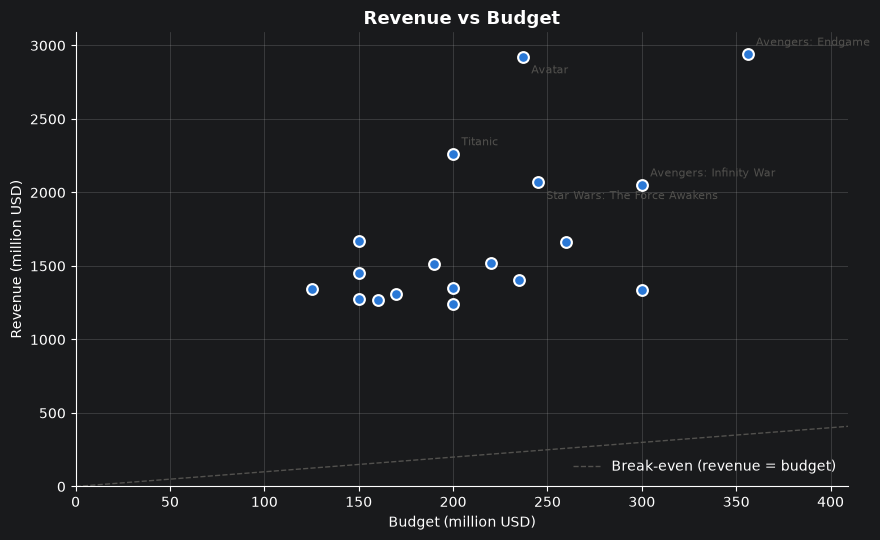

In [8]:
# 3.1 Revenue vs Budget
budget_revenue_pdf = movies_df.select("title", "budget_musd", "revenue_musd").dropna().toPandas()
plots.plot_revenue_vs_budget(budget_revenue_pdf)

**3.1 Revenue vs Budget:** every film earned far more than its budget (all points well above break-even).
Budget is only loosely linked to revenue: *Avatar* (~$237M) out-earned *Age of Ultron* (~$365M) by more than double.

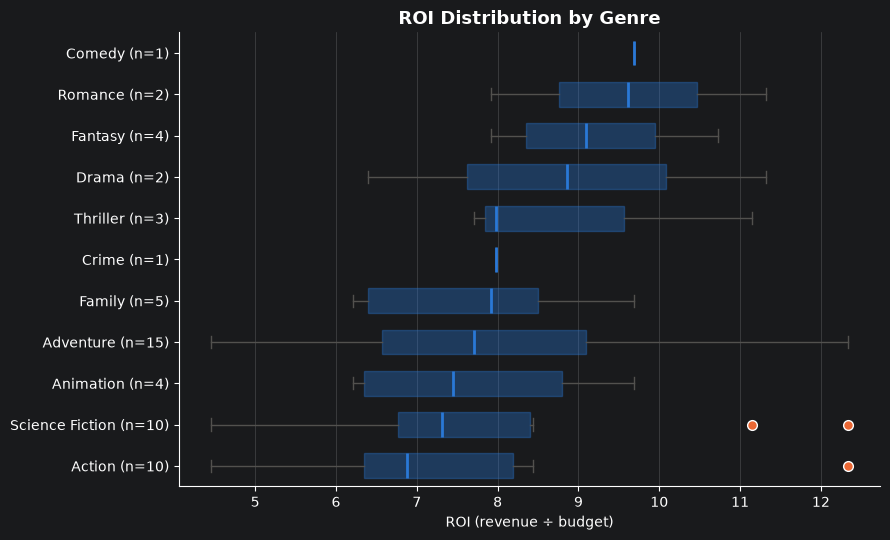

In [9]:
# 3.2 ROI distribution by genre (a film counts once in each of its genres)
roi_genre_pdf = (
    movies_df
    .select(F.explode(cleaning.split_names("genres")).alias("genre"), "roi")
    .dropna()
    .toPandas()
)
plots.plot_roi_by_genre(roi_genre_pdf)

**3.2 ROI by genre:** [genre] has the highest median ROI ([x]×) but only [n] films; Adventure (n=15) is the most
reliable comparison. Genres with 1–2 films should not be over-interpreted.

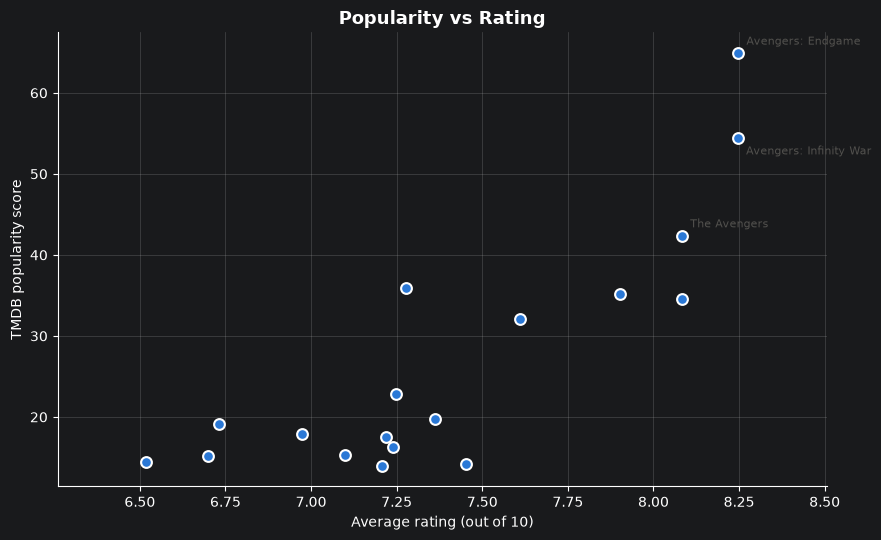

In [10]:
# 3.3 Popularity vs Rating
popularity_pdf = movies_df.select("title", "vote_average", "popularity").dropna().toPandas()
plots.plot_popularity_vs_rating(popularity_pdf)

**3.3 Popularity vs rating:** [higher-rated films tend to be / are not clearly] more popular; [title] is the most popular.
Popularity is a daily TMDB snapshot.

2026-11-04 16:58:54,051 INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-11-04 16:58:54,052 INFO matplotlib.category: Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


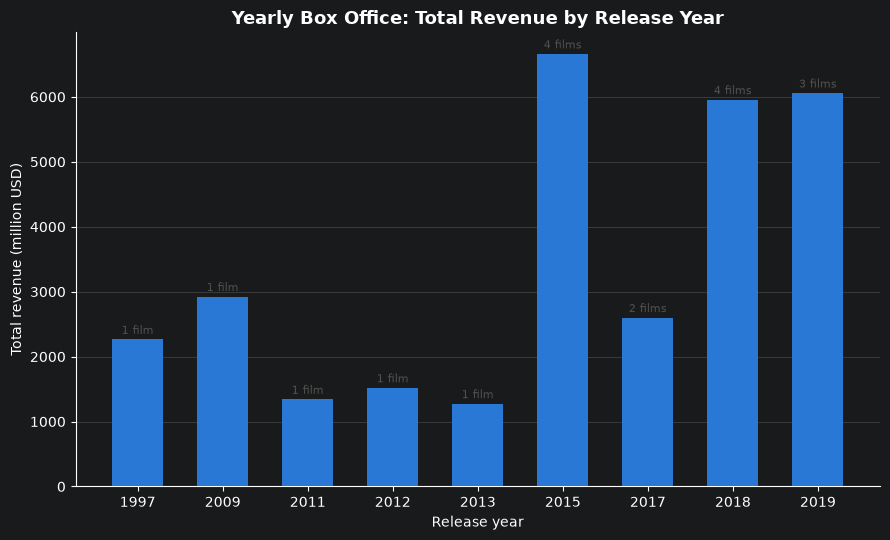

In [11]:
# 3.4 Yearly box office trends
yearly_pdf = (
    movies_df
    .filter(F.col("release_date").isNotNull())
    .groupBy(F.year("release_date").alias("year"))
    .agg(F.round(F.sum("revenue_musd"), 2).alias("total_revenue_musd"),
         F.count("*").alias("movies"))
    .orderBy("year")
    .toPandas()
)
plots.plot_yearly_box_office(yearly_pdf)

**3.4 Yearly trends:** 2015 had the highest total (4 films). Yearly totals mostly reflect how many of these 18 films
were released that year, so they describe this sample, not the whole film market.

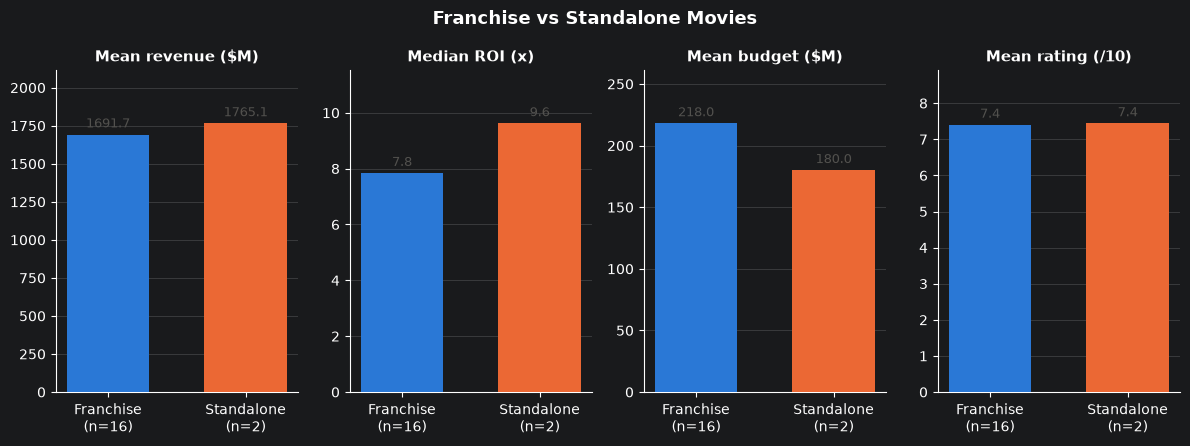

In [12]:
# 3.5 Franchise vs standalone (reuses the section 2.3 comparison table)
comparison_pdf = kpis.compare_franchise_vs_standalone(movies_df).toPandas()
plots.plot_franchise_vs_standalone(comparison_pdf)

**3.5 Franchise vs standalone:** standalone films show a higher median ROI and a lower mean budget, driven by
*Titanic*; with only 2 standalone films (vs 16) this is indicative, not conclusive.

## 4. Conclusions
- **All 18 films were highly profitable**; revenue is only loosely related to budget, so bigger budgets do not guarantee bigger returns.
- **Avatar** has the highest revenue and one of the highest ROIs; **The Avengers Collection** is the most successful franchise
  in total; **James Cameron** is the most successful director.
- **Franchise films** earn more in total but cost more; the 2 **standalone** films had a higher median ROI.
- Both required **searches return no movies**, because the dataset contains no Bruce Willis, Uma Thurman or Tarantino films;
  the search logic was validated on people who are in the data.

**Limitations:** only 18 blockbusters (not a representative sample); just 2 standalone films; popularity is a daily
snapshot; revenue figures are not adjusted for inflation (*Titanic* is from 1997).

**Next steps:** fetch a larger, more varied sample (e.g. via TMDB's discover endpoint) and adjust revenue for inflation.